In [9]:
%pip install xgboost

  Using cached xgboost-3.3.0-py3-none-win_amd64.whl.metadata (2.0 kB)
   ---------------------------------------- 0.0/69.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/69.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/69.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/69.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/69.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/69.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/69.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/69.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/69.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/69.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/69.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/69.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/69.5 MB ? eta -:--:--
   -----------------

ERROR: Could not install packages due to an OSError: [WinError 32] The process cannot access the file because it is being used by another process: 'C:\\Users\\Lenovo\\AppData\\Local\\Temp\\pip-unpack-5js_bvtr\\xgboost-3.3.0-py3-none-win_amd64.whl'
Consider using the `--user` option or check the permissions.



In [11]:


%pip install xgboost
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, confusion_matrix, classification_report, mean_squared_error)
import xgboost as xgb

model_df = pd.read_csv('mortality_modeling_table.csv')

# Feature set
numeric_feats = ['age_clean', 'weight_clean', 'height_clean', 'bmi_recalculated',
                  'baseline_who_stage', 'baseline_cd4', 'n_lab_events', 'days_on_treatment']
categorical_feats = ['sex', 'baseline_vl_status', 'subcity_clean']

# Impute numeric: median (robust to outliers)
for col in numeric_feats:
    model_df[col] = model_df[col].fillna(model_df[col].median())

# Impute categorical: explicit "Unknown" category
for col in categorical_feats:
    model_df[col] = model_df[col].fillna('Unknown').astype(str)

# Encode categoricals
encoders = {}
for col in categorical_feats:
    le = LabelEncoder()
    model_df[col + '_enc'] = le.fit_transform(model_df[col])
    encoders[col] = le

feature_cols = numeric_feats + [c + '_enc' for c in categorical_feats]
X = model_df[feature_cols]
y = model_df['died']

print("Feature matrix shape:", X.shape)
print("Features used:", feature_cols)
print("\nTarget distribution:")
print(y.value_counts())

  Using cached xgboost-3.3.0-py3-none-win_amd64.whl.metadata (2.0 kB)
   ---------------------------------------- 0.0/69.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/69.5 MB ? eta -:--:--
   ---------------------------------------- 0.3/69.5 MB ? eta -:--:--
   ---------------------------------------- 0.5/69.5 MB 1.8 MB/s eta 0:00:39
    --------------------------------------- 1.0/69.5 MB 2.1 MB/s eta 0:00:33
    --------------------------------------- 1.6/69.5 MB 2.2 MB/s eta 0:00:32
   - -------------------------------------- 2.4/69.5 MB 2.3 MB/s eta 0:00:30
   - -------------------------------------- 2.6/69.5 MB 2.3 MB/s eta 0:00:30
   - -------------------------------------- 3.4/69.5 MB 2.4 MB/s eta 0:00:28
   -- ------------------------------------- 4.2/69.5 MB 2.5 MB/s eta 0:00:27
   -- ------------------------------------- 4.7/69.5 MB 2.6 MB/s eta 0:00:26
   -- ------------------------------------- 5.0/69.5 MB 2.6 MB/s eta 0:00:26
   --- --------------------


[notice] A new release of pip is available: 25.2 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


NameError: name 'pd' is not defined

In [12]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, confusion_matrix, classification_report, mean_squared_error)

model_df = pd.read_csv('mortality_modeling_table.csv')
print("Loaded shape:", model_df.shape)
print(model_df.head())

FileNotFoundError: [Errno 2] No such file or directory: 'mortality_modeling_table.csv'

In [13]:
import os
print("Current working directory:", os.getcwd())
print("\nFiles here:")
for f in os.listdir():
    if f.endswith('.csv'):
        print(" ", f)
        

Current working directory: c:\Users\Lenovo\OneDrive\Desktop\CEM.analysis\data understanding

Files here:
  age_cleaned.csv
  all_labs_events_clean.csv
  cd4_trend_summary.csv
  CEM_deduped.csv
  CEM_final_preprocessed.csv
  geography_cleaned.csv
  lab_events_clean.csv
  medication_cleaned.csv
  patient_id_refined.csv
  patient_status_cleaned.csv
  vitals_cleaned.csv
  vl_suppression_summary.csv
  who_stage_split_clean.csv


In [14]:
import pandas as pd
import numpy as np

# Load the pieces we need from your saved cleaned files
df = pd.read_csv('CEM_final_preprocessed.csv', low_memory=False)
lab_events = pd.read_csv('lab_events_clean.csv', low_memory=False)
lab_events['test_date'] = pd.to_datetime(lab_events['test_date'], errors='coerce')

print("df shape:", df.shape)
print("lab_events shape:", lab_events.shape)
print("\ndf columns sample (checking key ones we'll need):")
needed_cols = ['patient_id', 'patient_status', 'age_clean', 'sex', 'health_facility',
               'subcity_clean', 'weight_clean', 'height_clean', 'bmi_recalculated',
               'who_hiv_stage_at_this_scre']
for c in needed_cols:
    print(f"  {c}: {'FOUND' if c in df.columns else 'MISSING'}")

df shape: (2478, 877)
lab_events shape: (5276, 8)

df columns sample (checking key ones we'll need):
  patient_id: FOUND
  patient_status: FOUND
  age_clean: FOUND
  sex: FOUND
  health_facility: FOUND
  subcity_clean: FOUND
  weight_clean: FOUND
  height_clean: FOUND
  bmi_recalculated: FOUND
  who_hiv_stage_at_this_scre: FOUND


In [15]:
# Build the mortality modeling table from scratch using the loaded df + lab_events

# TARGET: mortality
model_df = df[['patient_id', 'patient_status']].copy()
model_df['died'] = (model_df['patient_status'] == 'died').astype(int)

# Baseline WHO stage (numeric)
def clean_stage(val):
    if pd.isna(val):
        return None
    s = str(val).strip().upper()
    roman = {'I': 1, 'II': 2, 'III': 3, 'IV': 4}
    if s in roman:
        return roman[s]
    if s in {'1', '2', '3', '4'}:
        return int(s)
    return None

demo = df[['patient_id', 'age_clean', 'sex', 'health_facility', 'subcity_clean']].copy()
demo['baseline_who_stage'] = df['who_hiv_stage_at_this_scre'].apply(clean_stage)

# Baseline vitals
vitals = df[['patient_id', 'weight_clean', 'height_clean', 'bmi_recalculated']].copy()

# Baseline CD4 (first numeric result each patient has) and viral load status
cd4_baseline = (lab_events[(lab_events['test_name'] == 'CD4') & (lab_events['status'] == 'numeric')]
                 .sort_values('test_date').groupby('patient_id')['value'].first()
                 .rename('baseline_cd4').reset_index())

vl_baseline_status = (lab_events[lab_events['test_name'] == 'ViralLoad']
                        .sort_values('test_date').groupby('patient_id')['status'].first()
                        .rename('baseline_vl_status').reset_index())

# Time on treatment / number of visits
visit_stats = lab_events.dropna(subset=['test_date']).groupby('patient_id').agg(
    n_lab_events=('test_date', 'count'),
    days_on_treatment=('test_date', lambda x: (x.max() - x.min()).days)
).reset_index()

# Merge everything into one table
model_df = (model_df
    .merge(demo, on='patient_id', how='left')
    .merge(vitals, on='patient_id', how='left')
    .merge(cd4_baseline, on='patient_id', how='left')
    .merge(vl_baseline_status, on='patient_id', how='left')
    .merge(visit_stats, on='patient_id', how='left'))

print("Modeling table shape:", model_df.shape)
print("\nTarget distribution:")
print(model_df['died'].value_counts())
print(f"Death rate: {model_df['died'].mean()*100:.2f}%")

print("\nMissingness per feature:")
print(model_df.drop(columns=['patient_id', 'patient_status']).isna().sum().sort_values(ascending=False))

model_df.to_csv('mortality_modeling_table.csv', index=False)
print("\nSaved mortality_modeling_table.csv")

Modeling table shape: (2478, 15)

Target distribution:
died
0    2368
1     110
Name: count, dtype: int64
Death rate: 4.44%

Missingness per feature:
baseline_vl_status    1023
baseline_cd4           662
days_on_treatment      345
n_lab_events           345
baseline_who_stage     292
sex                    223
subcity_clean          206
bmi_recalculated       153
height_clean           140
weight_clean            89
age_clean               83
health_facility          3
died                     0
dtype: int64

Saved mortality_modeling_table.csv


In [16]:
from sklearn.preprocessing import LabelEncoder

model_df = pd.read_csv('mortality_modeling_table.csv')

numeric_feats = ['age_clean', 'weight_clean', 'height_clean', 'bmi_recalculated',
                  'baseline_who_stage', 'baseline_cd4', 'n_lab_events', 'days_on_treatment']
categorical_feats = ['sex', 'baseline_vl_status', 'subcity_clean']

# Impute numeric: median (robust to outliers, which we know this data has)
for col in numeric_feats:
    model_df[col] = model_df[col].fillna(model_df[col].median())

# Impute categorical: explicit "Unknown" category, kept visible rather than guessed
for col in categorical_feats:
    model_df[col] = model_df[col].fillna('Unknown').astype(str)

# Encode categoricals to numbers for the models
encoders = {}
for col in categorical_feats:
    le = LabelEncoder()
    model_df[col + '_enc'] = le.fit_transform(model_df[col])
    encoders[col] = le

feature_cols = numeric_feats + [c + '_enc' for c in categorical_feats]
X = model_df[feature_cols]
y = model_df['died']

print("Feature matrix shape:", X.shape)
print("Features used:", feature_cols)
print("\nAny remaining missing values in X?", X.isna().sum().sum())
print("\nTarget distribution:")
print(y.value_counts())

Feature matrix shape: (2478, 11)
Features used: ['age_clean', 'weight_clean', 'height_clean', 'bmi_recalculated', 'baseline_who_stage', 'baseline_cd4', 'n_lab_events', 'days_on_treatment', 'sex_enc', 'baseline_vl_status_enc', 'subcity_clean_enc']

Any remaining missing values in X? 0

Target distribution:
died
0    2368
1     110
Name: count, dtype: int64


In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train: {X_train.shape[0]} rows ({y_train.sum()} deaths, {y_train.mean()*100:.2f}%)")
print(f"Test:  {X_test.shape[0]} rows ({y_test.sum()} deaths, {y_test.mean()*100:.2f}%)")

Train: 1982 rows (88 deaths, 4.44%)
Test:  496 rows (22 deaths, 4.44%)


In [18]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC

models = {
    'Decision Tree': DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, max_depth=6, class_weight='balanced', random_state=42),
    'SVM': SVC(kernel='rbf', probability=True, class_weight='balanced', random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=200, max_depth=4, learning_rate=0.1, random_state=42)
}

fitted_models = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    fitted_models[name] = model
    print(f"{name}: trained")

Decision Tree: trained
Random Forest: trained
SVM: trained
Gradient Boosting: trained


In [19]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, confusion_matrix, mean_squared_error)
from sklearn.model_selection import cross_val_score, StratifiedKFold

results = []
for name, model in fitted_models.items():
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    auc = roc_auc_score(y_test, y_proba)
    mse = mean_squared_error(y_test, y_proba)
    cm = confusion_matrix(y_test, y_pred)

    cv_scores = cross_val_score(model, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=42), scoring='roc_auc')

    results.append({
        'Model': name, 'Accuracy': acc, 'Precision': prec, 'Recall': rec,
        'F1': f1, 'ROC_AUC': auc, 'MSE': mse, 'CV_AUC_mean': cv_scores.mean(), 'CV_AUC_std': cv_scores.std()
    })

    print(f"\n{'='*50}\n{name}\n{'='*50}")
    print(f"Accuracy:  {acc:.3f}")
    print(f"Precision: {prec:.3f}")
    print(f"Recall:    {rec:.3f}")
    print(f"F1-Score:  {f1:.3f}")
    print(f"ROC-AUC:   {auc:.3f}")
    print(f"MSE:       {mse:.3f}")
    print(f"5-fold CV ROC-AUC: {cv_scores.mean():.3f} (+/- {cv_scores.std():.3f})")
    print("\nConfusion Matrix:")
    print(f"                Predicted: Survived  Predicted: Died")
    print(f"Actual: Survived      {cm[0][0]:5d}            {cm[0][1]:5d}")
    print(f"Actual: Died          {cm[1][0]:5d}            {cm[1][1]:5d}")

results_df = pd.DataFrame(results)
print("\n\n=== FULL MODEL COMPARISON ===")
print(results_df.to_string(index=False))
results_df.to_csv('model_comparison_results.csv', index=False)
print("\nSaved model_comparison_results.csv")


Decision Tree
Accuracy:  0.778
Precision: 0.114
Recall:    0.591
F1-Score:  0.191
ROC-AUC:   0.749
MSE:       0.137
5-fold CV ROC-AUC: 0.776 (+/- 0.044)

Confusion Matrix:
                Predicted: Survived  Predicted: Died
Actual: Survived        373              101
Actual: Died              9               13

Random Forest
Accuracy:  0.921
Precision: 0.242
Recall:    0.364
F1-Score:  0.291
ROC-AUC:   0.798
MSE:       0.073
5-fold CV ROC-AUC: 0.825 (+/- 0.013)

Confusion Matrix:
                Predicted: Survived  Predicted: Died
Actual: Survived        449               25
Actual: Died             14                8

SVM
Accuracy:  0.716
Precision: 0.106
Recall:    0.727
F1-Score:  0.185
ROC-AUC:   0.758
MSE:       0.041
5-fold CV ROC-AUC: 0.739 (+/- 0.019)

Confusion Matrix:
                Predicted: Survived  Predicted: Died
Actual: Survived        339              135
Actual: Died              6               16

Gradient Boosting
Accuracy:  0.950
Precision: 0.200
Recall:  

=== Feature Importance (Random Forest) ===
baseline_cd4              0.179094
subcity_clean_enc         0.169263
bmi_recalculated          0.132940
days_on_treatment         0.131176
n_lab_events              0.082473
weight_clean              0.076655
age_clean                 0.074052
baseline_vl_status_enc    0.055976
height_clean              0.052230
baseline_who_stage        0.031521
sex_enc                   0.014619
dtype: float64


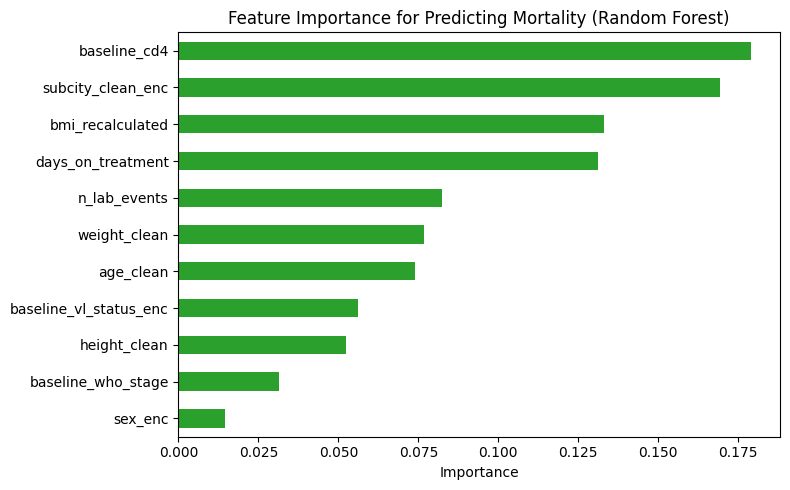

In [20]:
import matplotlib.pyplot as plt

rf_model = fitted_models['Random Forest']
importances = pd.Series(rf_model.feature_importances_, index=feature_cols).sort_values(ascending=False)

print("=== Feature Importance (Random Forest) ===")
print(importances)

plt.figure(figsize=(8, 5))
importances.plot(kind='barh', color='#2ca02c')
plt.gca().invert_yaxis()
plt.title('Feature Importance for Predicting Mortality (Random Forest)')
plt.xlabel('Importance')
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150)
plt.show()

In [21]:
print(model_df.groupby('subcity_clean')['died'].agg(['count', 'sum', 'mean']).sort_values('mean', ascending=False))

                              count  sum  mean
subcity_clean                                 
N/K                               1    1   1.0
L/N                               1    1   1.0
jeledu                            1    1   1.0
suleleta                          1    1   1.0
Outside Addis Ababa (tigray)      1    1   1.0
...                             ...  ...   ...
welete                            1    0   0.0
wolega                            1    0   0.0
woliso                            1    0   0.0
wolkite                           1    0   0.0
zeway                             1    0   0.0

[130 rows x 3 columns]


In [22]:
# Group any subcity with fewer than 10 patients into "Other" - keeps real signal, removes noise
subcity_counts = model_df['subcity_clean'].value_counts()
common_subcities = subcity_counts[subcity_counts >= 10].index
model_df['subcity_grouped'] = model_df['subcity_clean'].where(
    model_df['subcity_clean'].isin(common_subcities), 'Other'
)

print("Subcity categories before:", model_df['subcity_clean'].nunique())
print("Subcity categories after grouping:", model_df['subcity_grouped'].nunique())
print(model_df.groupby('subcity_grouped')['died'].agg(['count', 'sum', 'mean']).sort_values('count', ascending=False))

# Re-encode with the grouped version and rebuild X
le_subcity = LabelEncoder()
model_df['subcity_grouped_enc'] = le_subcity.fit_transform(model_df['subcity_grouped'].astype(str))

feature_cols_v2 = ['age_clean', 'weight_clean', 'height_clean', 'bmi_recalculated',
                    'baseline_who_stage', 'baseline_cd4', 'n_lab_events', 'days_on_treatment',
                    'sex_enc', 'baseline_vl_status_enc', 'subcity_grouped_enc']
X_v2 = model_df[feature_cols_v2]
y_v2 = model_df['died']

print("\nNew feature matrix shape:", X_v2.shape)

Subcity categories before: 130
Subcity categories after grouping: 16
                                   count  sum      mean
subcity_grouped                                        
Addis Ketema                         355    6  0.016901
Yeka                                 348    9  0.025862
Nifas Silk-Lafto                     272   44  0.161765
Kirkos                               247   18  0.072874
Addis Ababa (subcity unspecified)    216    5  0.023148
Unknown                              206    4  0.019417
Bole                                 187    5  0.026738
Other                                162    9  0.055556
Arada                                159    1  0.006289
Gulele                               106    3  0.028302
Kolfe Keranio                         77    2  0.025974
Lideta                                62    3  0.048387
Outside Addis Ababa (burayu)          37    1  0.027027
Outside Addis Ababa (oromiya)         19    0  0.000000
Outside Addis Ababa (sebeta)       

=== Random Forest (corrected subcity grouping) ===
Accuracy:  0.923
Precision: 0.278
Recall:    0.455
F1-Score:  0.345
ROC-AUC:   0.800

=== Corrected Feature Importance ===
baseline_cd4              0.181843
subcity_grouped_enc       0.165804
days_on_treatment         0.134914
bmi_recalculated          0.129844
n_lab_events              0.087205
age_clean                 0.074459
weight_clean              0.072152
baseline_vl_status_enc    0.053363
height_clean              0.053051
baseline_who_stage        0.032303
sex_enc                   0.015062
dtype: float64


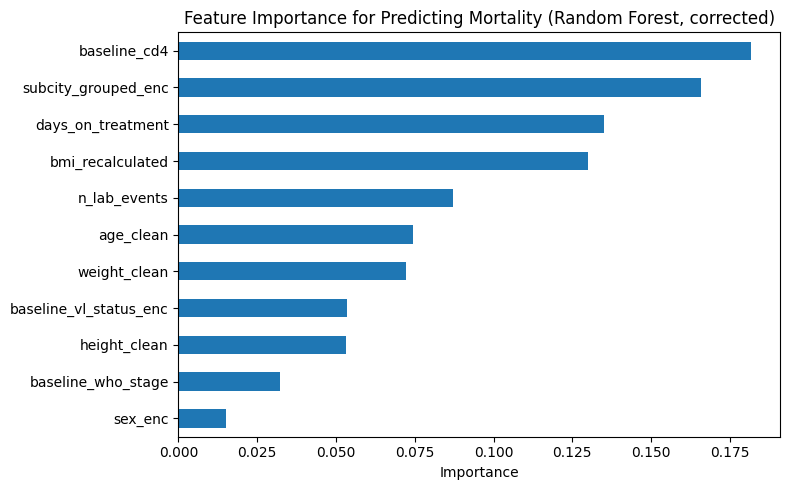

In [23]:
X_train_v2, X_test_v2, y_train_v2, y_test_v2 = train_test_split(
    X_v2, y_v2, test_size=0.2, random_state=42, stratify=y_v2
)

rf_v2 = RandomForestClassifier(n_estimators=200, max_depth=6, class_weight='balanced', random_state=42)
rf_v2.fit(X_train_v2, y_train_v2)

y_pred_v2 = rf_v2.predict(X_test_v2)
y_proba_v2 = rf_v2.predict_proba(X_test_v2)[:, 1]

print("=== Random Forest (corrected subcity grouping) ===")
print(f"Accuracy:  {accuracy_score(y_test_v2, y_pred_v2):.3f}")
print(f"Precision: {precision_score(y_test_v2, y_pred_v2, zero_division=0):.3f}")
print(f"Recall:    {recall_score(y_test_v2, y_pred_v2, zero_division=0):.3f}")
print(f"F1-Score:  {f1_score(y_test_v2, y_pred_v2, zero_division=0):.3f}")
print(f"ROC-AUC:   {roc_auc_score(y_test_v2, y_proba_v2):.3f}")

importances_v2 = pd.Series(rf_v2.feature_importances_, index=feature_cols_v2).sort_values(ascending=False)
print("\n=== Corrected Feature Importance ===")
print(importances_v2)

plt.figure(figsize=(8, 5))
importances_v2.plot(kind='barh', color='#1f77b4')
plt.gca().invert_yaxis()
plt.title('Feature Importance for Predicting Mortality (Random Forest, corrected)')
plt.xlabel('Importance')
plt.tight_layout()
plt.savefig('feature_importance_corrected.png', dpi=150)
plt.show()